In [1]:
import sys
from pathlib import Path
if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
DATA_DIR = Path('/content/drive/MyDrive/DeepMinds')   # shared folder: holds project_utils.py + torch_models.py
sys.path.append(str(DATA_DIR))
FIG_DIR = DATA_DIR / 'figures'; FIG_DIR.mkdir(exist_ok=True)
LOG = DATA_DIR / 'results_log.csv'

Mounted at /content/drive


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
log = pd.read_csv(LOG)
log = log[log['Split'] == 'val']
print(log.groupby(['hp_family', 'hp_experiment']).size())

def style(ax, title, xlabel):
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel('Validation F1')
    ax.grid(axis='y', color='#e1e0d9', lw=0.8); ax.spines[['top', 'right']].set_visible(False)

hp_family  hp_experiment
CNN        main              1
           sweep            10
LR         main              1
MLP        main              1
RF         main              1
dtype: int64


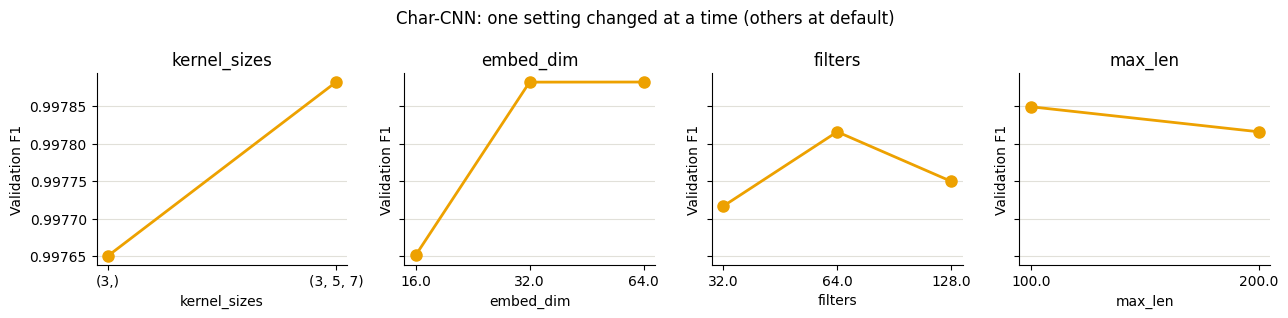

In [3]:
#CNN sweep: one small panel per setting
cnn = log[(log['hp_family'] == 'CNN') & (log['hp_experiment'] == 'sweep')]
if cnn.empty or 'hp_swept' not in cnn:
    raise SystemExit('No CNN sweep rows yet: run week2/A3_cnn_sweep first, then rerun this cell.')
cnn = cnn.drop_duplicates(['hp_swept', 'Model'])
settings = ['hp_kernel_sizes', 'hp_embed_dim', 'hp_filters', 'hp_max_len']
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
for ax, s in zip(axes, settings):
    rows = cnn[cnn['hp_swept'] == s[3:]].copy()
    if s != 'hp_kernel_sizes':
        rows = rows.sort_values(s, key=lambda c: c.astype(float))
    ax.plot(rows[s].astype(str), rows['F1'], marker='o', ms=8, lw=2, color='#eda100')
    style(ax, s[3:], s[3:])
fig.suptitle('Char-CNN: one setting changed at a time (others at default)')
fig.tight_layout(); fig.savefig(FIG_DIR / 'sweep_cnn.png', dpi=200); plt.show()


/tmp/ipykernel_1371/3360777427.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[1].legend(frameon=False); style(axes[1], 'Random Forest', 'n_estimators')
/tmp/ipykernel_1371/3360777427.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[2].legend(frameon=False); style(axes[2], 'MLP', 'hidden layers')


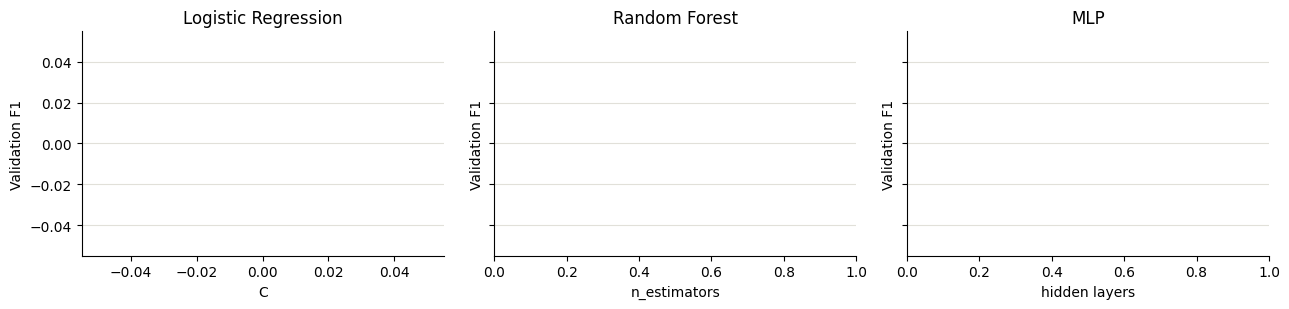

In [4]:
#feature-model sweeps (url22 only)
fm = log[(log['hp_experiment'] == 'sweep') & (log['hp_family'].isin(['LR', 'RF', 'MLP']))]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
lr = fm[fm['hp_family'] == 'LR'].sort_values('hp_C')
axes[0].plot(lr['hp_C'].astype(str), lr['F1'], marker='o', ms=8, lw=2, color='#2a78d6'); style(axes[0], 'Logistic Regression', 'C')
rf = fm[fm['hp_family'] == 'RF']
for depth, grp in rf.groupby(rf['hp_max_depth'].fillna('None').astype(str)):
    grp = grp.sort_values('hp_n_estimators')
    axes[1].plot(grp['hp_n_estimators'].astype(str), grp['F1'], marker='o', ms=8, lw=2, label=f'max_depth={depth}')
axes[1].legend(frameon=False); style(axes[1], 'Random Forest', 'n_estimators')
mlp = fm[fm['hp_family'] == 'MLP']
for drop, grp in (mlp.groupby('hp_dropout') if len(mlp) else []):
    axes[2].plot(grp['hp_hidden'].astype(str), grp['F1'], marker='o', ms=8, lw=2, label=f'dropout={drop}')
axes[2].legend(frameon=False); style(axes[2], 'MLP', 'hidden layers')
fig.tight_layout(); fig.savefig(FIG_DIR / 'sweep_feature_models.png', dpi=200); plt.show()

